# Image augmentation walkthrough: CLAHE and high-pass

This notebook explains the process behind `scripts/augment_images.py` and the functions in
`src/utils/augmentation.py`. The question: **do these augmentations make crevasses easier to see
in NISAR tiles?**

Steps:
1. Choose and load tiles that show crevasses.
2. Look at what a tile is.
3. CLAHE, step by step.
4. High-pass filtering, step by step.
5. Compare the methods.

The script (`make augment-images`) samples tiles at random. In this notebook we choose the
tiles ourselves, so we can look at ones where crevasses are visible.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import gaussian_filter

sys.path.insert(0, str(Path.cwd().parent / "scripts"))  # so we can import augment_images

import augment_images
from utils.augmentation import clahe, high_pass

## 1. Choose the tiles

A tile is identified by its **frame** (the `.h5` file) and its **row and column** in the 4096-pixel
grid. Change `FRAME_NAME` and `TILES_TO_USE` in the next cell to look at other tiles. Tiles are cut
with the same code as Label Studio (`labelstudio/tileserver/tileserver.py`, imported by the script
and not modified), so a tile here is the same patch you see when labeling.

The default tiles come from frame `024_077_A_140` and were picked by eye from an overview of the
frame. Both show thin, crack-like features:
- **(4, 2):** a long thin dark crack in the lower left, and fine lines on the right.
- **(5, 3):** long linear cracks running from the top left toward the bottom.

These are visual picks, not confirmed labels. Check them with a mentor or in Label Studio.

In [2]:
image_dir = augment_images.DEFAULT_IMAGE_DIR
output_dir = augment_images.DEFAULT_OUTPUT_DIR
tile_size = augment_images.TILE_SIZE

FRAME_NAME = "NISAR_L2_PR_GCOV_024_077_A_140"  # start of the .h5 file name
TILES_TO_USE = [(4, 2), (5, 3)]  # (row, column) in the 4096-pixel grid

In [ ]:
tileserver = augment_images.load_tileserver(image_dir, output_dir / "stats_cache")
frame = next(image_dir.rglob(f"{FRAME_NAME}*.h5"))
stats = tileserver.get_stats(frame)  # the frame's display range, cached after the first time

tiles = {}  # (row, column) -> tile
for row, col in TILES_TO_USE:
    tiles[(row, col)] = tileserver.render_tile(frame, stats, tile_size, row, col)
print(frame.name)
list(tiles) 

Computing display range for NISAR_L2_PR_GCOV_024_077_A_140_4005_SHSH_A_20260701T135211_20260701T135247_P05023_N_F_J_001.h5 (one-time) ...


NISAR_L2_PR_GCOV_024_077_A_140_4005_SHSH_A_20260701T135211_20260701T135247_P05023_N_F_J_001.h5


[(4, 2), (5, 3)]

## 2. What is a tile?

A tile is a 4096 x 4096 array of `uint8` gray levels (the radar backscatter in dB, stretched to
0-255). Gray level **0 means nodata** (outside the radar swath), and 1-255 is real data.
Both functions expect this format.

**How to read the plot below:** the black curve is the **histogram** (how many pixels have each
gray level). The blue curve is the **CDF**, the running total of that histogram, scaled to the
same height. Where the CDF rises steeply, many pixels share similar gray levels. A tile with
low contrast has a CDF that rises steeply in a narrow band. Nodata pixels (0) are left out.

tile (4, 2) shape (4096, 4096) dtype uint8
min 0 max 255 nodata fraction 0.0


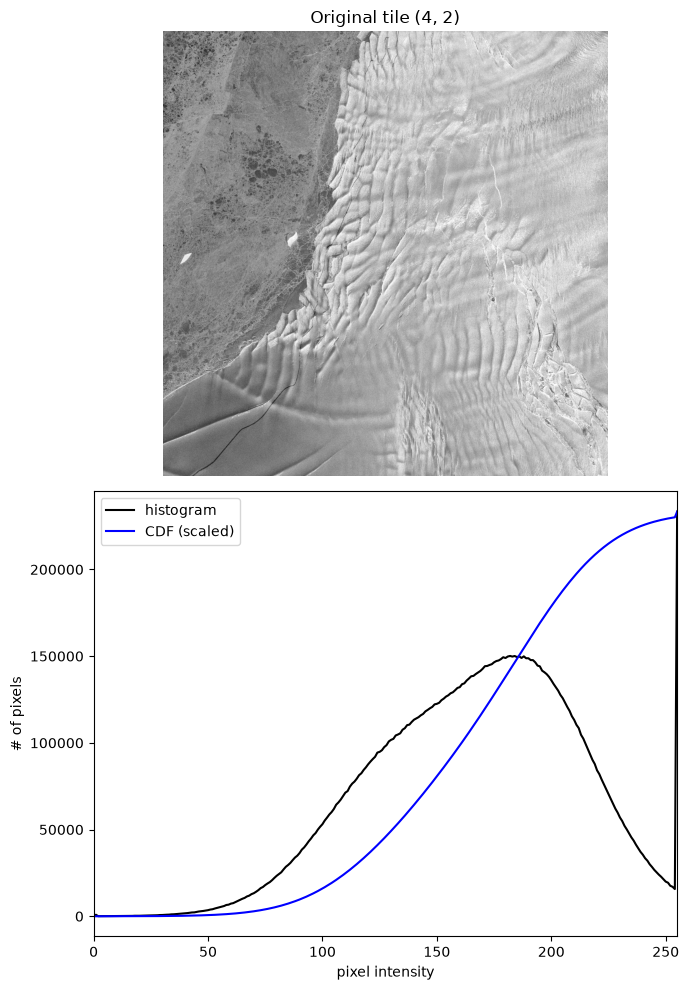

In [15]:
N_LEVELS = 256  # gray levels 0..255

def histogram_and_cdf(image: np.ndarray, max_value: int = N_LEVELS - 1) -> tuple:
    """Histogram of the valid pixels (nodata = 0 is left out) and its CDF.

    The CDF (cumulative distribution function) is scaled to the height of the histogram, so
    both curves fit on the same plot.
    """
    valid_pixels = image[image > 0]
    hist = np.bincount(valid_pixels.ravel(), minlength=max_value + 1)
    cdf = hist.cumsum()
    cdf_scaled = cdf * float(hist.max()) / cdf.max()
    return hist, cdf_scaled


def show_image_and_histogram(image: np.ndarray, title: str, ax_image: plt.Axes, ax_hist: plt.Axes) -> None:
    """Draw the image on ax_image, and its histogram (black) and CDF (blue) on ax_hist."""
    hist, cdf_scaled = histogram_and_cdf(image)
    ax_image.imshow(image, cmap="gray", vmin=0, vmax=N_LEVELS - 1)
    ax_image.set_title(title)
    ax_image.axis("off")
    ax_hist.plot(hist, color="black", label="histogram")
    ax_hist.plot(cdf_scaled, color="b", label="CDF (scaled)")
    ax_hist.set_xlim(0, N_LEVELS - 1)
    ax_hist.set_xlabel("pixel intensity")
    ax_hist.set_ylabel("# of pixels")
    ax_hist.legend()


first = next(iter(tiles))
tile = tiles[first]
print("tile", first, "shape", tile.shape, "dtype", tile.dtype)
print("min", tile.min(), "max", tile.max(), "nodata fraction", round((tile == 0).mean(), 3))

fig, (ax_image, ax_hist) = plt.subplots(2, 1, figsize=(7, 10))
show_image_and_histogram(tile, f"Original tile {first}", ax_image, ax_hist)
plt.tight_layout()
plt.show()

## 3. CLAHE (Contrast Limited Adaptive Histogram Equalization)

**Idea:** normal histogram equalization stretches the contrast of the whole image at once. CLAHE
does it in small local windows, so faint features in a dull area get stretched too. The
`clip_limit` stops it from over-amplifying noise (higher = stronger).

`clahe()` calls `skimage.exposure.equalize_adapthist`, then sets nodata pixels back to 0.

Below: the input (left) and the CLAHE output (right), each with its histogram and CDF. After
CLAHE, the histogram should be spread over more gray levels and the CDF should be closer to a
straight diagonal line. Because CLAHE works in local regions and has a clip limit, it won't be
perfectly flat like global histogram equalization.

output dtype float64 range 0.0 to 1.0


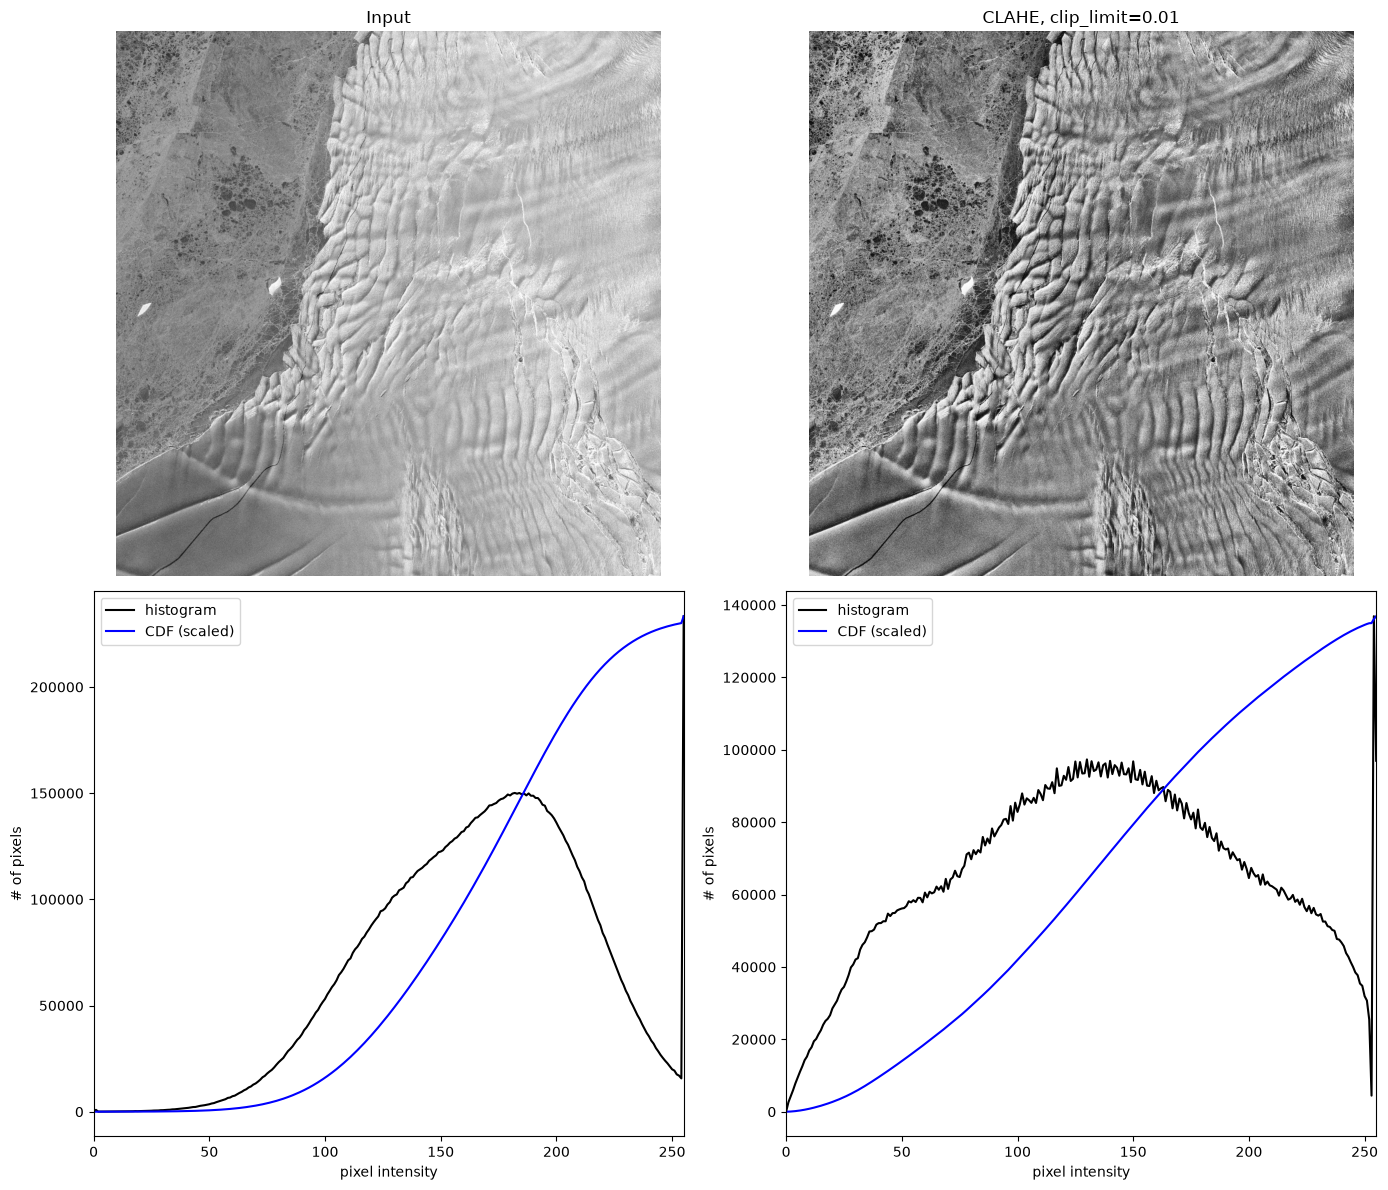

In [16]:
out = clahe(tile)  # default clip_limit=0.01
print("output dtype", out.dtype, "range", out.min(), "to", out.max())

# CLAHE returns floats between 0 and 1. Convert to 0..255 so the histogram has the same axis.
out_gray = np.rint(out * (N_LEVELS - 1)).astype(np.uint8)

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
show_image_and_histogram(tile, "Input", axes[0, 0], axes[1, 0])
show_image_and_histogram(out_gray, "CLAHE, clip_limit=0.01", axes[0, 1], axes[1, 1])
plt.tight_layout()
plt.show()

Effect of the parameter: a zoomed-in crop (top-left 1024 x 1024 pixels) with different `clip_limit` values.

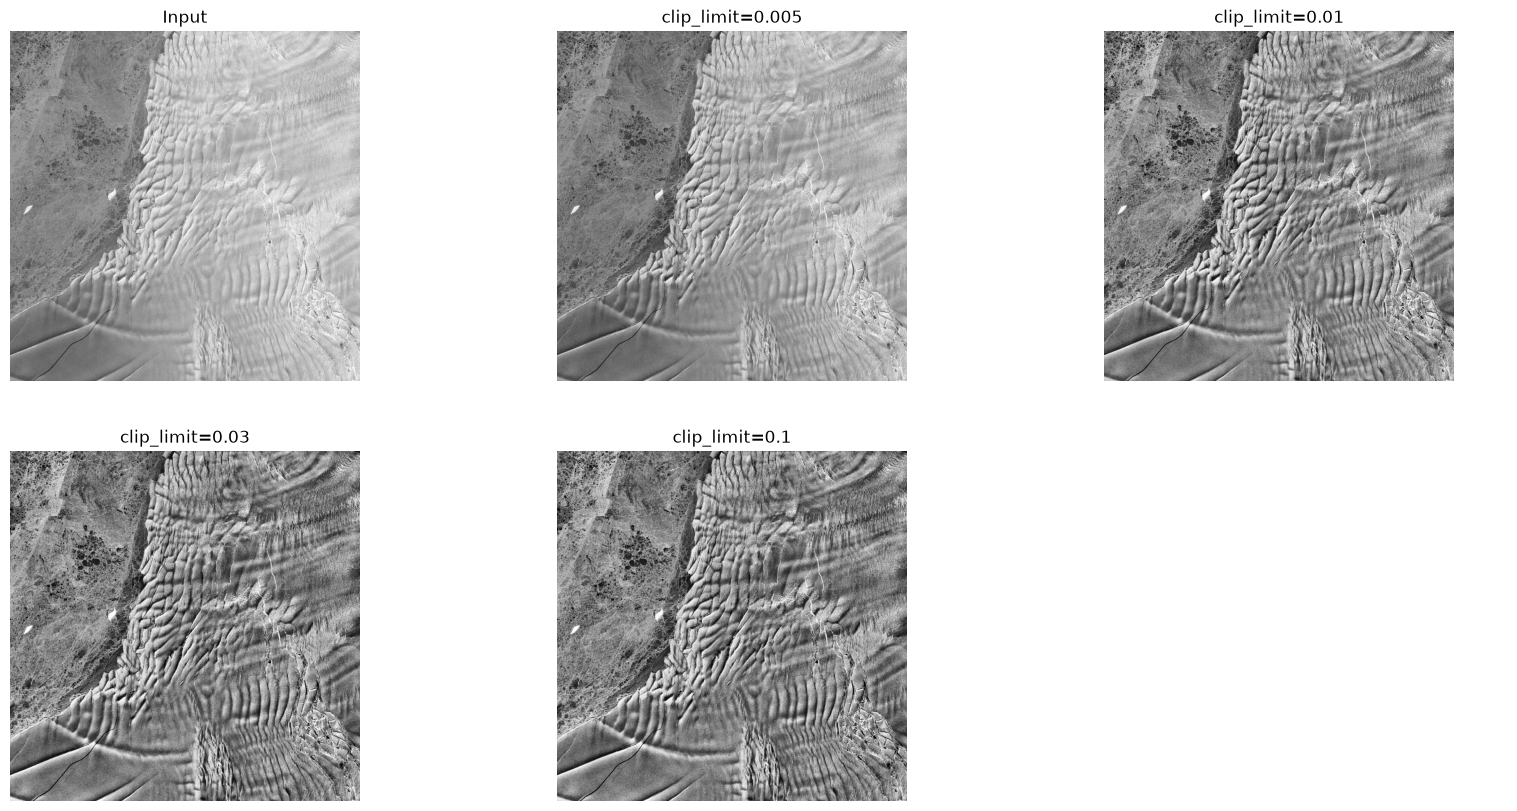

In [17]:
crop = (slice(1536, 2560), slice(3072, 4096))  # center-right 1024 x 1024 (rows, columns)
clip_limits = [0.005, 0.01, 0.03, 0.1]

fig, axes = plt.subplots(2, 3, figsize=(20, 10))
axes[0,0].imshow(tile, cmap="gray", vmin=0, vmax=255)
axes[0,0].set_title("Input")
for ax, clip_limit in zip(axes.flat[1:], clip_limits):
    ax.imshow(clahe(tile, clip_limit), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"clip_limit={clip_limit}")
for ax in axes.flat:
    ax.axis("off")
plt.show()

## 4. High-pass filtering

**Idea:** a Gaussian blur keeps only the slow, large-scale brightness changes. If we subtract the
blur from the original, what is left is the small stuff, like crevasses. `sigma` is the blur size
in pixels: features much smaller than `sigma` are kept.

`high_pass()` does three things, shown below one at a time:
1. blur the tile,
2. subtract the blur from the original,
3. stretch the result between its 1st and 99th percentile, and set nodata back to 0.

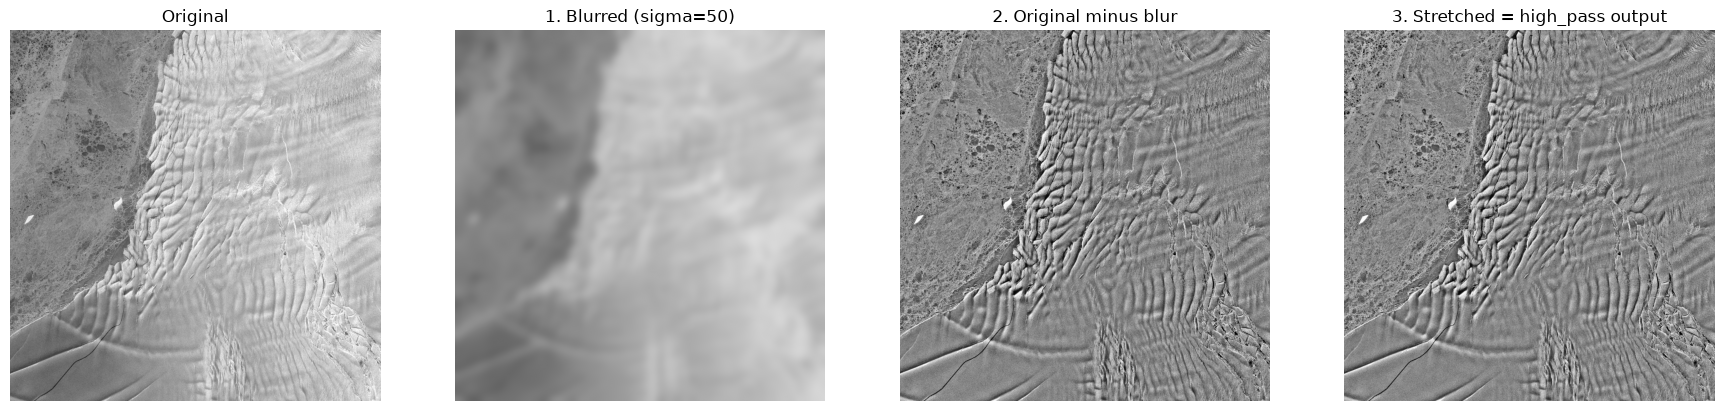

Same as high_pass(): True


In [18]:
sigma = 50
valid = tile != 0
image = tile.astype(float)

blurred = gaussian_filter(image, sigma)  # step 1
difference = image - blurred  # step 2
low, high = np.percentile(difference[valid], [1, 99])  # step 3
stretched = np.clip((difference - low) / (high - low), 0, 1)
stretched[~valid] = 0

fig, axes = plt.subplots(1, 4, figsize=(22, 6))
axes[0].imshow(image, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original")
axes[1].imshow(blurred, cmap="gray", vmin=0, vmax=255)
axes[1].set_title(f"1. Blurred (sigma={sigma})")
axes[2].imshow(difference, cmap="gray", vmin=low, vmax=high)
axes[2].set_title("2. Original minus blur")
axes[3].imshow(stretched, cmap="gray", vmin=0, vmax=1)
axes[3].set_title("3. Stretched = high_pass output")
for ax in axes:
    ax.axis("off")
plt.show()

# The function gives the same answer as the steps above:
print("Same as high_pass():", np.allclose(stretched, high_pass(tile, sigma)))

Effect of the parameter: the same crop with different `sigma` values.

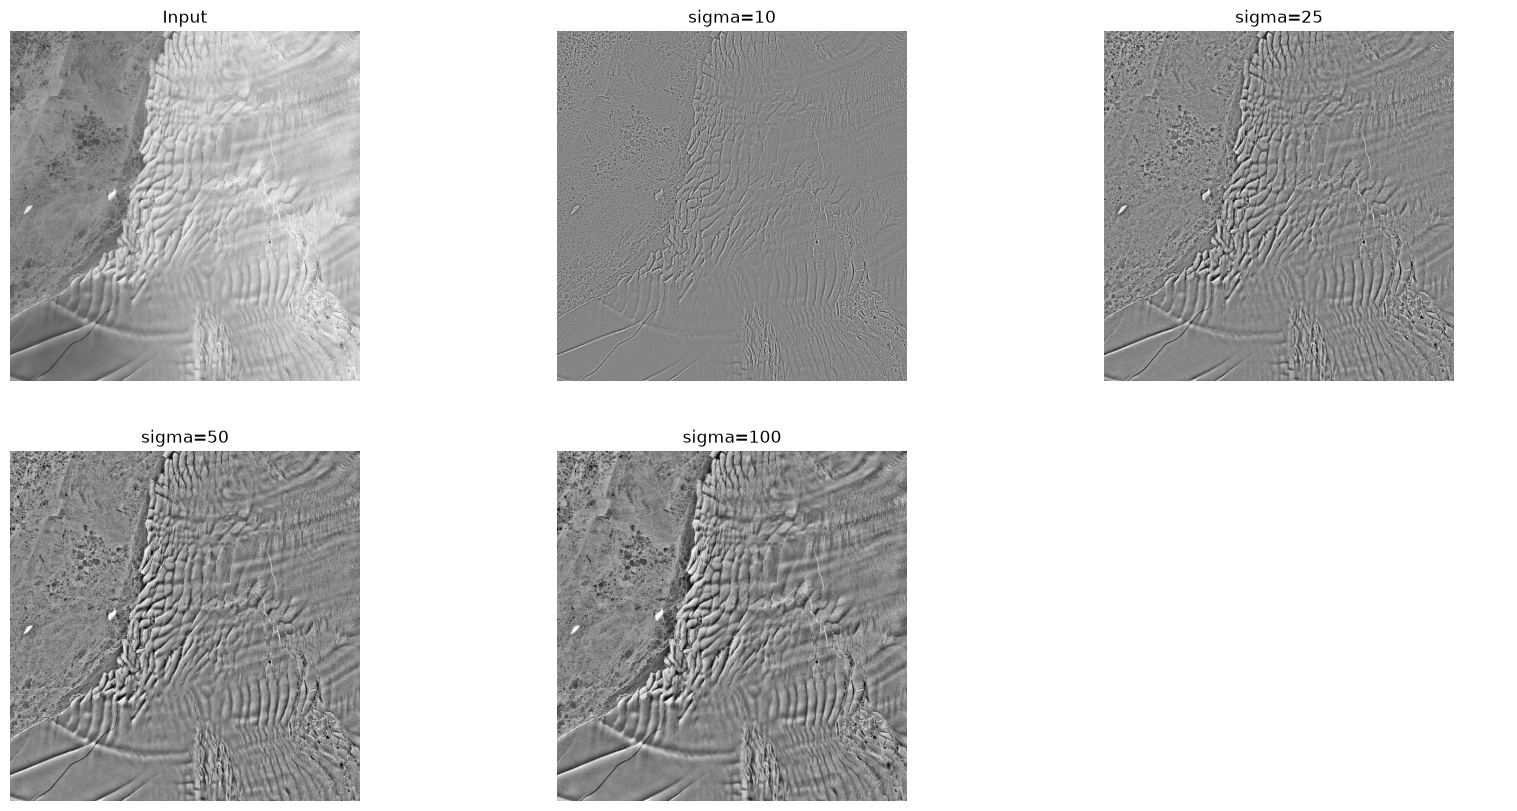

In [19]:
sigmas = [10, 25, 50, 100]

fig, axes = plt.subplots(2,3, figsize=(20, 10))
axes[0,0].imshow(tile, cmap="gray", vmin=0, vmax=255)
axes[0,0].set_title("Input")
for ax, s in zip(axes.flat[1:], sigmas):
    ax.imshow(high_pass(tile, s), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"sigma={s}")
for ax in axes.flat:
    ax.axis("off")
plt.show()

## 5. Compare the methods on every sampled tile

One row per tile: input, CLAHE, high-pass. These are the same comparisons the script saves as
figures. Use them for the conclusions in `scripts/README.md`: which method made crevasses more
visible, and where did each help or hurt?

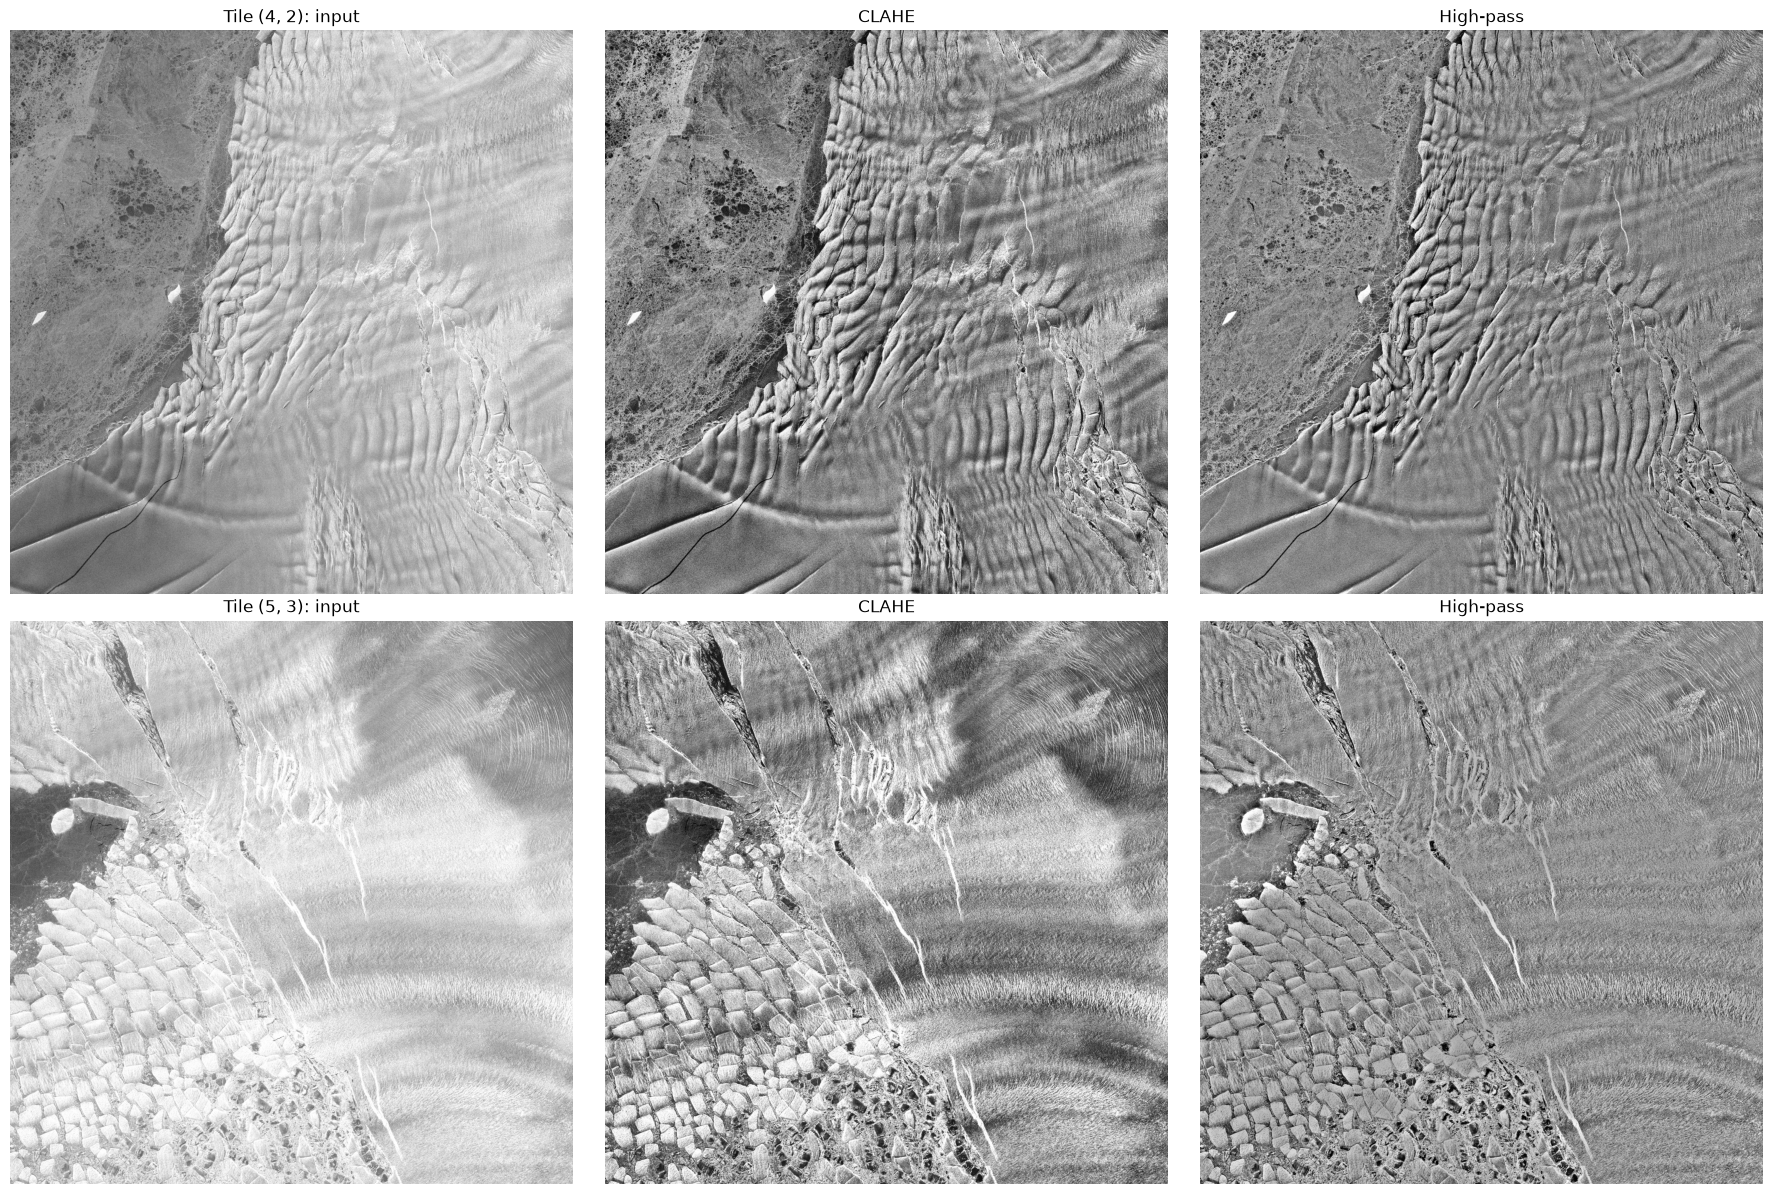

In [67]:
fig, axes = plt.subplots(len(tiles), 3, figsize=(18, 6 * len(tiles)), squeeze=False)
for row_axes, ((row, col), t) in zip(axes, tiles.items()):
    row_axes[0].imshow(t, cmap="gray", vmin=0, vmax=255)
    row_axes[0].set_title(f"Tile ({row}, {col}): input")
    row_axes[1].imshow(clahe(t), cmap="gray", vmin=0, vmax=1)
    row_axes[1].set_title("CLAHE")
    row_axes[2].imshow(high_pass(t), cmap="gray", vmin=0, vmax=1)
    row_axes[2].set_title("High-pass")
    for ax in row_axes:
        ax.axis("off")
plt.tight_layout()
plt.show()